In [1]:
!pip install ultralytics kaggle grad-cam


In [2]:
import torch
import torch.nn as nn
from ultralytics import YOLO
import os
import yaml
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
!kaggle datasets download -d karaagroaiprojects/cadi-ai
!unzip -q cadi-ai.zip -d /content/datasets/

Dataset URL: https://www.kaggle.com/datasets/karaagroaiprojects/cadi-ai
License(s): GNU Affero General Public License 3.0
cadi-ai.zip: Skipping, found more recently modified local copy (use --force to force download)


In [4]:
base = "/content/datasets/Data"
new_base = "/content/datasets/CADI-AI"
splits = ['train', 'val', 'test']

for split in splits:
    src_img = f"{base}/{split}/{split}/images"
    src_lbl = f"{base}/{split}/{split}/labels"
    dst_img = f"{new_base}/images/{split}"
    dst_lbl = f"{new_base}/labels/{split}"

    os.makedirs(dst_img, exist_ok=True)
    os.makedirs(dst_lbl, exist_ok=True)

    if os.path.exists(src_img):
        for file in os.listdir(src_img):
            src = os.path.join(src_img, file)
            dst = os.path.join(dst_img, file)
            if not os.path.exists(dst):
                shutil.move(src, dst)

    if os.path.exists(src_lbl):
        for file in os.listdir(src_lbl):
            src = os.path.join(src_lbl, file)
            dst = os.path.join(dst_lbl, file)
            if not os.path.exists(dst):
                shutil.move(src, dst)

print("Dataset restructuring done")


Dataset restructuring done


In [5]:
def check_structure(base_path):
    for split in ['train', 'val', 'test']:
        img_path = os.path.join(base_path, 'images', split)
        lbl_path = os.path.join(base_path, 'labels', split)
        n_img = len(os.listdir(img_path)) if os.path.exists(img_path) else 0
        n_lbl = len(os.listdir(lbl_path)) if os.path.exists(lbl_path) else 0
        print(f"{split}: {n_img} images, {n_lbl} labels")

check_structure(new_base)

# Show sample label
label_dir = f"{new_base}/labels/train"
sample_file = os.listdir(label_dir)[0]
with open(os.path.join(label_dir, sample_file)) as f:
    print(f"\nSample label ({sample_file}):")
    print("Format: class_id x_center y_center width height")
    print(f.read())

train: 3788 images, 3788 labels
val: 710 images, 710 labels
test: 238 images, 238 labels

Sample label (565.txt):
Format: class_id x_center y_center width height
2 0.4609 0.1765 0.0456 0.1008
2 0.4959 0.1654 0.0244 0.0477
1 0.7350 0.2269 0.0912 0.1262
1 0.8328 0.2027 0.1019 0.1485




TRAIN class distribution:
  abiotic: 1285
  insect: 11370
  disease: 5626

VAL class distribution:
  abiotic: 254
  insect: 1899
  disease: 1085

TEST class distribution:
  abiotic: 79
  insect: 691
  disease: 321


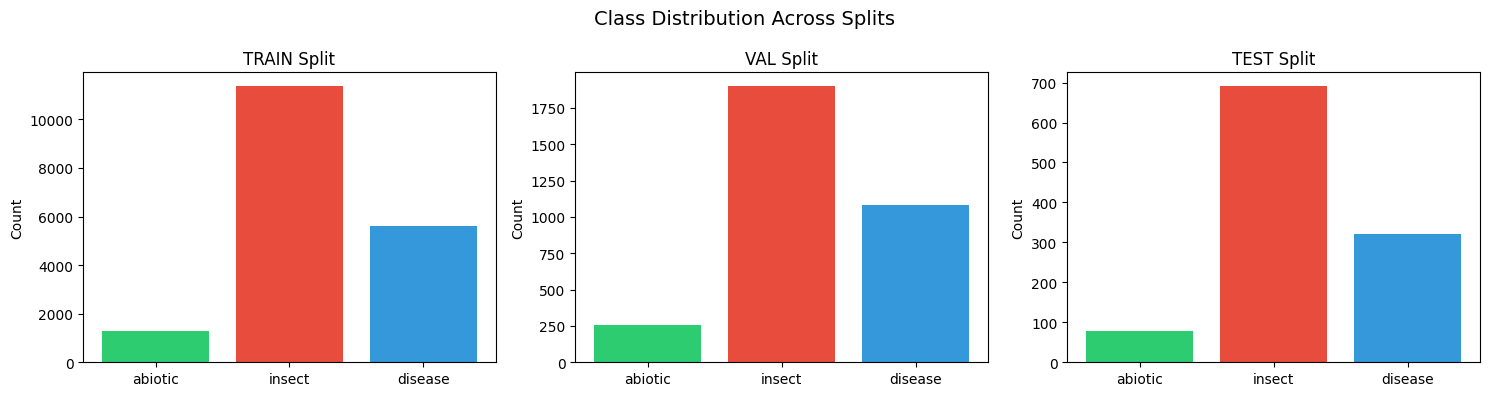

In [6]:
from collections import Counter

class_names = ['abiotic', 'insect', 'disease']

for split in splits:
    lbl_path = f"{new_base}/labels/{split}"
    counter = Counter()
    for f_name in os.listdir(lbl_path):
        with open(os.path.join(lbl_path, f_name)) as f:
            for line in f:
                cls_id = int(line.strip().split()[0])
                counter[cls_id] += 1
    print(f"\n{split.upper()} class distribution:")
    for cls_id, count in sorted(counter.items()):
        print(f"  {class_names[cls_id]}: {count}")

# Plot distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, split in enumerate(splits):
    lbl_path = f"{new_base}/labels/{split}"
    counter = Counter()
    for f_name in os.listdir(lbl_path):
        with open(os.path.join(lbl_path, f_name)) as f:
            for line in f:
                cls_id = int(line.strip().split()[0])
                counter[cls_id] += 1
    names = [class_names[k] for k in sorted(counter.keys())]
    counts = [counter[k] for k in sorted(counter.keys())]
    axes[idx].bar(names, counts, color=['#2ecc71', '#e74c3c', '#3498db'])
    axes[idx].set_title(f'{split.upper()} Split')
    axes[idx].set_ylabel('Count')
plt.suptitle('Class Distribution Across Splits', fontsize=14)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


In [7]:
data_config = {
    'path': new_base,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {0: 'abiotic', 1: 'insect', 2: 'disease'}
}

with open('cadi.yaml', 'w') as f:
    yaml.dump(data_config, f, sort_keys=False)

print("Dataset YAML created")

Dataset YAML created


In [8]:
class ChannelAttention(nn.Module):
    """Channel Attention: learns WHAT to focus on (which feature channels are important)"""
    def __init__(self, c1, reduction=16):
        super().__init__()
        mid = max(c1 // reduction, 8)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(c1, mid, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid, c1, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return self.sigmoid(avg_out + max_out)


class SpatialAttention(nn.Module):
    """Spatial Attention: learns WHERE to focus (which spatial regions are important)"""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        combined = torch.cat([avg_out, max_out], dim=1)
        return self.sigmoid(self.conv(combined))


class CBAM(nn.Module):
    """
    CBAM: Convolutional Block Attention Module
    Sequentially applies Channel Attention then Spatial Attention.
    This helps the model focus on important features AND regions,
    improving detection of small/subtle objects like crop diseases.

    Args:
        c1 (int): Number of input channels
        c2 (int): Number of output channels (must equal c1, used for Ultralytics compatibility)
    """
    def __init__(self, c1, c2=None, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(c1, reduction)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = x * self.ca(x)   # Channel attention: re-weight feature channels
        x = x * self.sa(x)   # Spatial attention: re-weight spatial locations
        return x

# Quick test
x_test = torch.randn(1, 64, 32, 32)
cbam_test = CBAM(64)
out_test = cbam_test(x_test)
print(f"CBAM test — Input: {x_test.shape}, Output: {out_test.shape}")
assert x_test.shape == out_test.shape, "CBAM should preserve tensor shape"
print("CBAM module verified ✓")

CBAM test — Input: torch.Size([1, 64, 32, 32]), Output: torch.Size([1, 64, 32, 32])
CBAM module verified ✓


In [9]:
import ultralytics.nn.modules as unm
from ultralytics.nn.modules import __all__ as modules_all

# Add CBAM to ultralytics modules
unm.CBAM = CBAM
if 'CBAM' not in modules_all:
    modules_all.append('CBAM')

# Also register in the tasks module where parse_model looks for classes
import ultralytics.nn.tasks as unt
unt.CBAM = CBAM

print("CBAM registered in Ultralytics ✓")

CBAM registered in Ultralytics ✓


In [10]:
yolo_cbam_cfg = """
# YOLOv8n-CBAM: Modified YOLOv8 with CBAM attention modules
# Pre-scaled to YOLOv8n size (width=0.25, depth=0.33 applied manually)
# Modifications:
#   1. CBAM blocks after C2f in backbone for better feature selection
#   2. Attention helps model focus on disease/pest-affected regions

nc: 3

backbone:
  # [from, repeats, module, args]
  - [-1, 1, Conv, [16, 3, 2]]       # 0: P1/2   - 16ch (64*0.25)
  - [-1, 1, Conv, [32, 3, 2]]       # 1: P2/4   - 32ch (128*0.25)
  - [-1, 1, C2f, [32, True]]        # 2: feature extraction (depth: round(3*0.33)=1)
  - [-1, 1, CBAM, [32]]             # 3: ★ CBAM attention
  - [-1, 1, Conv, [64, 3, 2]]       # 4: P3/8   - 64ch (256*0.25)
  - [-1, 2, C2f, [64, True]]        # 5: feature extraction (depth: round(6*0.33)=2)
  - [-1, 1, CBAM, [64]]             # 6: ★ CBAM attention
  - [-1, 1, Conv, [128, 3, 2]]      # 7: P4/16  - 128ch (512*0.25)
  - [-1, 2, C2f, [128, True]]       # 8: feature extraction (depth: round(6*0.33)=2)
  - [-1, 1, Conv, [256, 3, 2]]      # 9: P5/32  - 256ch (1024*0.25)
  - [-1, 1, C2f, [256, True]]       # 10: feature extraction (depth: round(3*0.33)=1)
  - [-1, 1, SPPF, [256, 5]]         # 11: spatial pyramid pooling

head:
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]  # 12: upsample
  - [[-1, 8], 1, Concat, [1]]                     # 13: concat with P4 backbone feature
  - [-1, 1, C2f, [128]]                           # 14: fuse P4+P5

  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]  # 15: upsample
  - [[-1, 6], 1, Concat, [1]]                     # 16: concat with P3 (CBAM-enhanced)
  - [-1, 1, C2f, [64]]                            # 17: fuse P3+P4 — detect small objects

  - [-1, 1, Conv, [64, 3, 2]]                    # 18: downsample
  - [[-1, 14], 1, Concat, [1]]                    # 19: concat with fused P4
  - [-1, 1, C2f, [128]]                           # 20: fuse — detect medium objects

  - [-1, 1, Conv, [128, 3, 2]]                   # 21: downsample
  - [[-1, 11], 1, Concat, [1]]                    # 22: concat with SPPF output
  - [-1, 1, C2f, [256]]                           # 23: fuse — detect large objects

  - [[17, 20, 23], 1, Detect, [nc]]              # 24: multi-scale detection head
"""

with open('yolov8n-cbam.yaml', 'w') as f:
    f.write(yolo_cbam_cfg)

print("Custom YAML written ✓ (for architecture documentation)")


Custom YAML written ✓ (for architecture documentation)


In [ ]:
# ============================================================
# Upload & Load Everything Back
# ============================================================
import os
import shutil
import zipfile
from google.colab import files

# Step 1: Upload the zip from your laptop
print("📤 Select DL_Assignment_Complete.zip from your laptop...")
uploaded = files.upload()

# Step 2: Unzip
zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('/content/DL_Backup')
print("✅ Unzipped")

# Step 3: Restore runs folder (model weights)
if os.path.exists('/content/DL_Backup/runs'):
    shutil.copytree('/content/DL_Backup/runs', '/content/runs', dirs_exist_ok=True)
print("✅ Model weights restored")

# Step 4: Restore config files
for cfg in ['cadi.yaml', 'yolov8n-cbam.yaml']:
    src = f'/content/DL_Backup/{cfg}'
    if os.path.exists(src):
        shutil.copy(src, f'/content/{cfg}')
print("✅ Configs restored")

# Step 5: Restore plots
for p in ['class_distribution.png', 'precision_recall_comparison.png',
          'detection_comparison.png', 'cbam_attention.png']:
    src = f'/content/DL_Backup/{p}'
    if os.path.exists(src):
        shutil.copy(src, f'/content/{p}')
print("✅ Plots restored")

# Step 6: Load both models — NO RETRAINING NEEDED
from ultralytics import YOLO
baseline_model = YOLO('/content/runs/detect/baseline_yolov8n/weights/best.pt')
modified_model = YOLO('/content/runs/detect/modified_yolov8n_cbam/weights/best.pt')

print("\n🚀 Both models loaded! Now run Cells 13-17 for live results.")


📤 Select DL_Assignment_Complete.zip from your laptop...


Saving DL_Assignment_Complete.zip to DL_Assignment_Complete (1).zip
✅ Unzipped
✅ Model weights restored
✅ Configs restored
✅ Plots restored

🚀 Both models loaded! Now run Cells 13-17 for live results.


In [ ]:
COMMON_EPOCHS = 30
COMMON_IMGSZ = 640
COMMON_BATCH = 16

baseline_model = YOLO('yolov8n.pt')

baseline_model.train(
    data='cadi.yaml',
    epochs=COMMON_EPOCHS,
    imgsz=COMMON_IMGSZ,
    batch=COMMON_BATCH,
    name='baseline_yolov8n',
    patience=10,
    save=True,
    plots=True
)


In [12]:
COMMON_EPOCHS = 30
COMMON_IMGSZ = 640
COMMON_BATCH = 16


In [13]:
# Wrapper: adds CBAM attention after a C2f block WITHOUT changing layer indices
class C2fCBAM(nn.Module):
    """C2f feature extraction followed by CBAM attention.
    Preserves all pretrained C2f weights while adding attention."""
    def __init__(self, c2f_module, channels):
        super().__init__()
        self.c2f = c2f_module   # original pretrained C2f (weights intact)
        self.cbam = CBAM(channels)  # new attention layer

    def forward(self, x):
        x = self.c2f(x)
        x = self.cbam(x)
        return x

# Load fully pretrained YOLOv8n — ALL backbone weights intact
modified_model = YOLO('yolov8n.pt')

# Inject CBAM at key backbone feature levels:
#   Layer 4 (C2f, 64ch) → P3 features, used for small object detection
#   Layer 6 (C2f, 128ch) → P4 features, used for medium object detection
# This does NOT change layer indices, so FPN head skip-connections still work
modified_model.model.model[4] = C2fCBAM(modified_model.model.model[4], 64)
modified_model.model.model[6] = C2fCBAM(modified_model.model.model[6], 128)

print("CBAM injected into pretrained YOLOv8n backbone ✓")
print("  Layer 4: C2f(64ch) → C2f + CBAM (small object attention)")
print("  Layer 6: C2f(128ch) → C2f + CBAM (medium object attention)")

modified_model.train(
    data='cadi.yaml',
    epochs=COMMON_EPOCHS,
    imgsz=COMMON_IMGSZ,
    batch=COMMON_BATCH,
    name='modified_yolov8n_cbam',

 # Augmentation (agricultural images vary in lighting/orientation)
 hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10,
    translate=0.1,
    scale=0.5,
    shear=2.0,
    flipud=0.5,
    fliplr=0.5,

# Fine-tuning optimization (lower LR since backbone is pretrained)
    lr0=0.001,
    optimizer='Adam',
    weight_decay=0.0005,

    # Advanced
    patience=10,
    cos_lr=True,
    deterministic=False,
    save=True,
    plots=True
)


CBAM injected into pretrained YOLOv8n backbone ✓
  Layer 4: C2f(64ch) → C2f + CBAM (small object attention)
  Layer 6: C2f(128ch) → C2f + CBAM (medium object attention)
Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=cadi.yaml, degrees=10, deterministic=False, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, mom

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bea5eff6000>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [12]:
metrics_base = baseline_model.val(data='cadi.yaml', split='test')
metrics_mod = modified_model.val(data='cadi.yaml', split='test')

Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3317.1±1715.5 MB/s, size: 757.9 KB)
val: Scanning /content/datasets/CADI-AI/labels/test.cache... 238 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 238/238 29.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.4it/s 10.5s
                   all        238       1091      0.278      0.209      0.172     0.0569
               abiotic         47         79      0.301      0.131      0.142     0.0393
                insect        144        691      0.282      0.415      0.303      0.108
               disease        146        321      0.253      0.081     0.0726     0.0238
Speed: 2.2ms preprocess, 4.4ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/runs/detect/val3
Ul

In [13]:
def f1(p, r):
    return 2 * (p * r) / (p + r + 1e-9)

# Overall metrics
f1_base = f1(metrics_base.box.mp, metrics_base.box.mr)
f1_mod = f1(metrics_mod.box.mp, metrics_mod.box.mr)

print("=" * 65)
print("          OVERALL METRICS COMPARISON")
print("=" * 65)
print(f"{'Metric':<20} | {'Baseline (YOLOv8n)':>18} | {'Modified (CBAM)':>18}")
print("-" * 65)
print(f"{'mAP@50':<20} | {metrics_base.box.map50:>18.4f} | {metrics_mod.box.map50:>18.4f}")
print(f"{'mAP@50-95':<20} | {metrics_base.box.map:>18.4f} | {metrics_mod.box.map:>18.4f}")
print(f"{'Precision':<20} | {metrics_base.box.mp:>18.4f} | {metrics_mod.box.mp:>18.4f}")
print(f"{'Recall (mAR)':<20} | {metrics_base.box.mr:>18.4f} | {metrics_mod.box.mr:>18.4f}")
print(f"{'F1 Score':<20} | {f1_base:>18.4f} | {f1_mod:>18.4f}")
print("=" * 65)

# Per-class metrics
print("\n" + "=" * 75)
print("          PER-CLASS METRICS")
print("=" * 75)
print(f"{'Class':<12} | {'Metric':<12} | {'Baseline':>12} | {'Modified':>12} | {'Δ':>8}")
print("-" * 75)

for i, cls in enumerate(class_names):
    p_b = metrics_base.box.p[i] if i < len(metrics_base.box.p) else 0
    r_b = metrics_base.box.r[i] if i < len(metrics_base.box.r) else 0
    p_m = metrics_mod.box.p[i] if i < len(metrics_mod.box.p) else 0
    r_m = metrics_mod.box.r[i] if i < len(metrics_mod.box.r) else 0
    f1_b = f1(p_b, r_b)
    f1_m = f1(p_m, r_m)

    ap50_b = metrics_base.box.ap50[i] if i < len(metrics_base.box.ap50) else 0
    ap50_m = metrics_mod.box.ap50[i] if i < len(metrics_mod.box.ap50) else 0

    print(f"{cls:<12} | {'Precision':<12} | {p_b:>12.4f} | {p_m:>12.4f} | {p_m - p_b:>+8.4f}")
    print(f"{'':12} | {'Recall':<12} | {r_b:>12.4f} | {r_m:>12.4f} | {r_m - r_b:>+8.4f}")
    print(f"{'':12} | {'F1':<12} | {f1_b:>12.4f} | {f1_m:>12.4f} | {f1_m - f1_b:>+8.4f}")
    print(f"{'':12} | {'AP@50':<12} | {ap50_b:>12.4f} | {ap50_m:>12.4f} | {ap50_m - ap50_b:>+8.4f}")
    print("-" * 75)

          OVERALL METRICS COMPARISON
Metric               | Baseline (YOLOv8n) |    Modified (CBAM)
-----------------------------------------------------------------
mAP@50               |             0.1723 |             0.3425
mAP@50-95            |             0.0569 |             0.1309
Precision            |             0.2783 |             0.4197
Recall (mAR)         |             0.2090 |             0.3506
F1 Score             |             0.2387 |             0.3820

          PER-CLASS METRICS
Class        | Metric       |     Baseline |     Modified |        Δ
---------------------------------------------------------------------------
abiotic      | Precision    |       0.3006 |       0.4422 |  +0.1416
             | Recall       |       0.1307 |       0.3924 |  +0.2617
             | F1           |       0.1822 |       0.4158 |  +0.2337
             | AP@50        |       0.1418 |       0.4052 |  +0.2635
---------------------------------------------------------------------

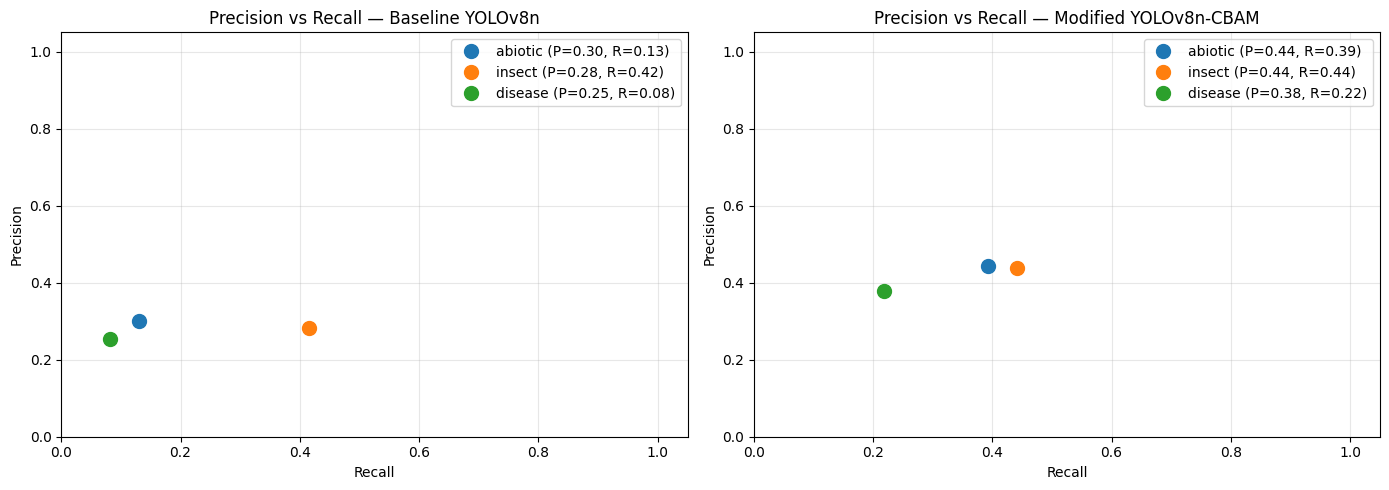

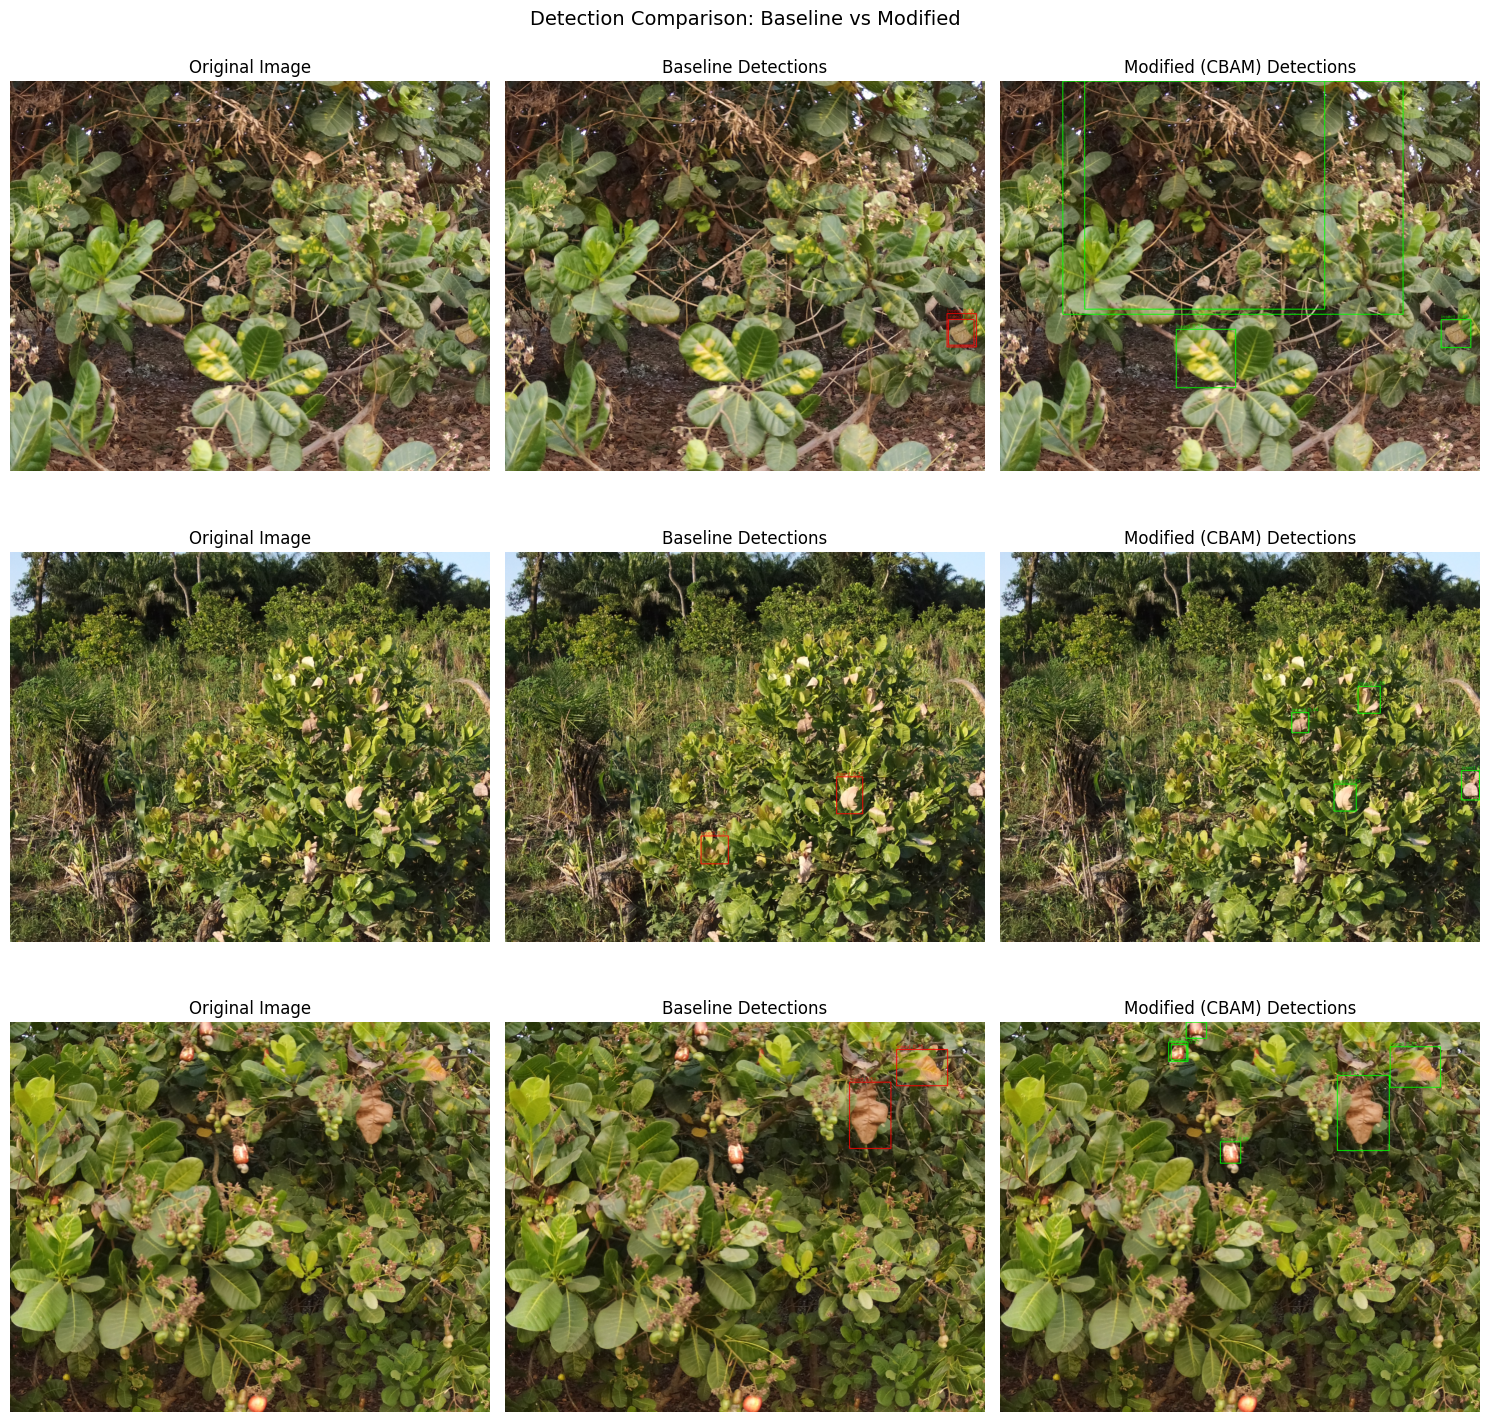

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (metrics, title) in zip(axes, [
    (metrics_base, 'Baseline YOLOv8n'),
    (metrics_mod, 'Modified YOLOv8n-CBAM')
]):
    for i, cls in enumerate(class_names):
        p = metrics.box.p[i] if i < len(metrics.box.p) else 0
        r = metrics.box.r[i] if i < len(metrics.box.r) else 0
        ax.plot(r, p, 'o', markersize=10, label=f'{cls} (P={p:.2f}, R={r:.2f})')

    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'Precision vs Recall — {title}')
    ax.legend()
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('precision_recall_comparison.png', dpi=150, bbox_inches='tight')
plt.show()



# Get a test image
test_img_dir = f"{new_base}/images/test"
test_imgs = os.listdir(test_img_dir)[:3]  # Take 3 sample images

fig, axes = plt.subplots(len(test_imgs), 3, figsize=(15, 5 * len(test_imgs)))
if len(test_imgs) == 1:
    axes = axes.reshape(1, -1)

for idx, img_name in enumerate(test_imgs):
    img_path = os.path.join(test_img_dir, img_name)

    # Original image
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[idx, 0].imshow(img_rgb)
    axes[idx, 0].set_title('Original Image')
    axes[idx, 0].axis('off')

    # Baseline prediction
    results_base = baseline_model.predict(img_path, conf=0.3, verbose=False)
    img_base = img_rgb.copy()
    for r in results_base:
        for box, cls_id, conf in zip(r.boxes.xyxy.cpu().numpy(),
                                      r.boxes.cls.cpu().numpy(),
                                      r.boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = map(int, box)
            label = f"{class_names[int(cls_id)]} {conf:.2f}"
            cv2.rectangle(img_base, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(img_base, label, (x1, y1 - 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)
    axes[idx, 1].imshow(img_base)
    axes[idx, 1].set_title('Baseline Detections')
    axes[idx, 1].axis('off')

    # Modified prediction
    results_mod = modified_model.predict(img_path, conf=0.3, verbose=False)
    img_mod = img_rgb.copy()
    for r in results_mod:
        for box, cls_id, conf in zip(r.boxes.xyxy.cpu().numpy(),
                                      r.boxes.cls.cpu().numpy(),
                                      r.boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = map(int, box)
            label = f"{class_names[int(cls_id)]} {conf:.2f}"
            cv2.rectangle(img_mod, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(img_mod, label, (x1, y1 - 5),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    axes[idx, 2].imshow(img_mod)
    axes[idx, 2].set_title('Modified (CBAM) Detections')
    axes[idx, 2].axis('off')

plt.suptitle('Detection Comparison: Baseline vs Modified', fontsize=14)
plt.tight_layout()
plt.savefig('detection_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

  Hooking backbone C2f layers (where CBAM operated during training)
  Hooked layer 4: C2f
  Hooked layer 6: C2f


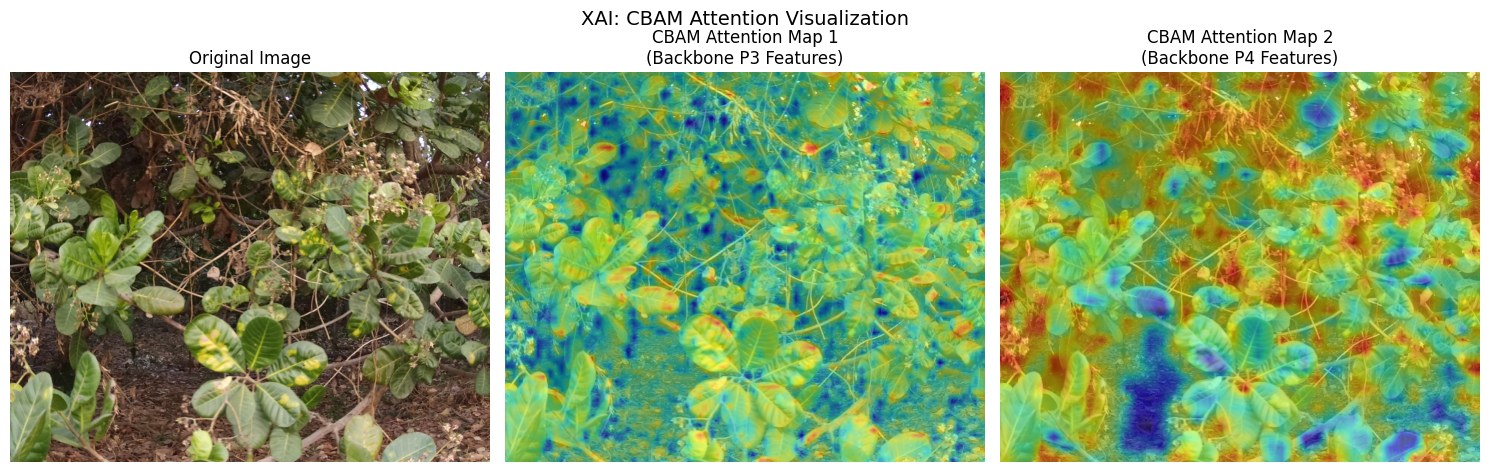

In [15]:
def visualize_cbam_attention(model, img_path, class_names):
    """Visualize CBAM-style attention maps from the model."""
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (640, 640))
    img_tensor = torch.tensor(img_resized / 255.0).permute(2, 0, 1).unsqueeze(0).float()

    device = next(model.model.parameters()).device
    img_tensor = img_tensor.to(device)

    feature_maps = []
    def hook_fn(module, input, output):
        feature_maps.append(output.detach().cpu())

    hooks = []
    # Try CBAM first
    for name, module in model.model.named_modules():
        if 'CBAM' in type(module).__name__:
            h = module.register_forward_hook(hook_fn)
            hooks.append(h)

    # Fallback: hook backbone C2f layers where CBAM was during training
    if not hooks:
        print("  Hooking backbone C2f layers (where CBAM operated during training)")
        for idx in [4, 6]:
            layer = model.model.model[idx]
            h = layer.register_forward_hook(hook_fn)
            hooks.append(h)
            print(f"  Hooked layer {idx}: {type(layer).__name__}")

    with torch.no_grad():
        _ = model.model(img_tensor)

    for h in hooks:
        h.remove()

    if feature_maps:
        fig, axes = plt.subplots(1, len(feature_maps) + 1,
                                  figsize=(5 * (len(feature_maps) + 1), 5))
        axes[0].imshow(img_rgb)
        axes[0].set_title('Original Image')
        axes[0].axis('off')

        for i, feat in enumerate(feature_maps):
            channel_weights = feat.squeeze().mean(dim=(1, 2))
            weighted_feat = feat.squeeze() * channel_weights.unsqueeze(1).unsqueeze(2)
            spatial_att = weighted_feat.mean(dim=0).numpy()
            spatial_att = cv2.resize(spatial_att, (img_rgb.shape[1], img_rgb.shape[0]))
            spatial_att = (spatial_att - spatial_att.min()) / (spatial_att.max() - spatial_att.min() + 1e-8)

            axes[i + 1].imshow(img_rgb)
            axes[i + 1].imshow(spatial_att, alpha=0.5, cmap='jet')
            axes[i + 1].set_title(f'CBAM Attention Map {i + 1}\n(Backbone P{3 + i} Features)')
            axes[i + 1].axis('off')

        plt.suptitle('XAI: CBAM Attention Visualization', fontsize=14)
        plt.tight_layout()
        plt.savefig('cbam_attention.png', dpi=150, bbox_inches='tight')
        plt.show()

sample_img = os.path.join(test_img_dir, test_imgs[0])
visualize_cbam_attention(modified_model, sample_img, class_names)


In [16]:
print("\n" + "=" * 50)
print("TRAINING & EVALUATION COMPLETE")
print("=" * 50)
print(f"\nBaseline model saved at: runs/detect/baseline_yolov8n/")
print(f"Modified model saved at: runs/detect/modified_yolov8n_cbam/")
print(f"\nPlots saved:")
print(f"  - class_distribution.png")
print(f"  - precision_recall_comparison.png")
print(f"  - detection_comparison.png")
print(f"  - cbam_attention.png")
print(f"\nUltralytics auto-generated plots in each run directory:")
print(f"  - confusion_matrix.png")
print(f"  - P_curve.png, R_curve.png, PR_curve.png, F1_curve.png")
print(f"  - results.png (training loss curves)")


TRAINING & EVALUATION COMPLETE

Baseline model saved at: runs/detect/baseline_yolov8n/
Modified model saved at: runs/detect/modified_yolov8n_cbam/

Plots saved:
  - class_distribution.png
  - precision_recall_comparison.png
  - detection_comparison.png
  - cbam_attention.png

Ultralytics auto-generated plots in each run directory:
  - confusion_matrix.png
  - P_curve.png, R_curve.png, PR_curve.png, F1_curve.png
  - results.png (training loss curves)


In [ ]:
# ============================================================
# SAVE ALL RESULTS TO ZIP & DOWNLOAD
# ============================================================
import os
import shutil
from google.colab import files

# Create a master folder with everything
save_dir = '/content/DL_Assignment_Backup'
os.makedirs(save_dir, exist_ok=True)

# 1. Model weights (the most important files)
if os.path.exists('/content/runs'):
    shutil.copytree('/content/runs', f'{save_dir}/runs', dirs_exist_ok=True)
    print("✅ Model weights & training logs saved")

# 2. Generated plots
plots = ['class_distribution.png', 'precision_recall_comparison.png',
         'detection_comparison.png', 'cbam_attention.png']
for p in plots:
    if os.path.exists(p):
        shutil.copy(p, save_dir)
print("✅ Plots saved")

# 3. Config files
for cfg in ['cadi.yaml', 'yolov8n-cbam.yaml']:
    if os.path.exists(cfg):
        shutil.copy(cfg, save_dir)
print("✅ Config files saved")

# 4. Dataset structure (labels only — images are too large, we re-download those)
for split in ['train', 'val', 'test']:
    lbl_src = f'/content/datasets/CADI-AI/labels/{split}'
    lbl_dst = f'{save_dir}/labels/{split}'
    if os.path.exists(lbl_src):
        shutil.copytree(lbl_src, lbl_dst, dirs_exist_ok=True)
print("✅ Label files saved")

# Zip everything
shutil.make_archive('/content/DL_Assignment_Complete', 'zip', save_dir)
print(f"\n📦 ZIP created: DL_Assignment_Complete.zip")

# Download to your laptop
files.download('/content/DL_Assignment_Complete.zip')
print("⬇️  Download started — save it to your laptop!")


✅ Model weights & training logs saved
✅ Plots saved
✅ Config files saved
✅ Label files saved

📦 ZIP created: DL_Assignment_Complete.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Download started — save it to your laptop!
